# Шаг 6. Заглядываем внутрь свёрточной сети

Нейросеть часто называют «чёрным ящиком», но свёрточную сеть можно частично **рассмотреть**:
- **фильтры первого слоя** — это крошечные картинки 3 × 3, их можно нарисовать;
- **карты признаков** — то, что видит сеть после каждого блока, — тоже картинки;
- **ошибки** сети подсказывают, что она поняла, а что нет.

> Нужна обученная сеть `cnn_aug.pt` — сначала выполните шаг 5.

**Структура примера (алгоритм):**
1. Загружаем обученную сеть и проверочные данные.
2. Рисуем 16 фильтров первого свёрточного слоя.
3. Пропускаем фото через блоки сети и рисуем карты признаков после каждого блока.
4. Считаем точность отдельно для кошек и для собак и таблицу путаницы 2 × 2.
5. Показываем ошибки, в которых сеть была **увереннее всего**.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Загружаем сеть и данные

`load_model(SimpleCNN(dropout=0.3), "cnn_aug")` создаёт пустую сеть той же архитектуры и загружает в неё обученные веса.
Архитектура должна совпадать с той, что обучалась, иначе веса «не влезут».

In [1]:
import matplotlib.pyplot as plt
import torch

from common import CLASSES, CLASSES_RU, CatsDogs, SimpleCNN, accuracy, load_model, predict_all, show

model = load_model(SimpleCNN(dropout=0.3), "cnn_aug")
test = CatsDogs(train=False)
print(f"Точность на проверке: {accuracy(model, test):.1%}")

Точность на проверке: 83.3%


## 2. Фильтры первого слоя

`model.features[0]` — первый слой `Conv2d`, его веса имеют форму `(16, 3, 3, 3)`: 16 фильтров, у каждого 3 канала по 3 × 3.
Каждый фильтр можно нарисовать как **цветную картинку 3 × 3**, если перевести веса в диапазон 0…1:
`(w − min) / (max − min)`. Серые фильтры почти не различают цвет, цветные — реагируют на конкретный оттенок.

Обычно среди фильтров первого слоя видны детекторы **границ** (светлое с одной стороны, тёмное с другой)
и детекторы **цветных пятен** — то же, что мы задавали вручную в шаге 2, только сеть нашла их сама.

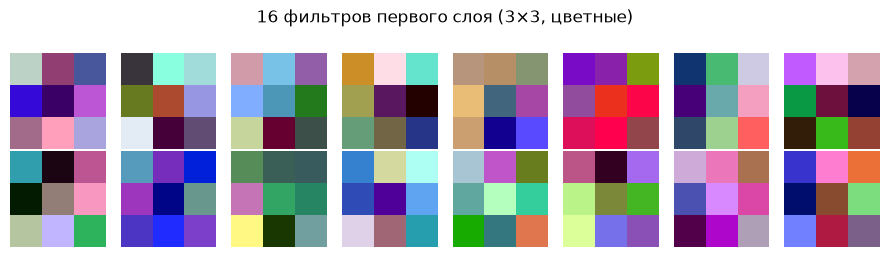

In [2]:
weights = model.features[0].weight.detach()          # (16, 3, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for ax, w in zip(axes.flat, weights):
    w = (w - w.min()) / (w.max() - w.min())          # веса → 0..1, чтобы показать как цвет
    ax.imshow(w.permute(1, 2, 0), interpolation="nearest")
    ax.axis("off")
fig.suptitle("16 фильтров первого слоя (3×3, цветные)")
plt.tight_layout()
plt.savefig("filters.png", dpi=100)
show()

## 3. Карты признаков после каждого блока

Пропускаем одно фото через слои `model.features` по очереди (как в шаге 4) и запоминаем результат после
каждого **пулинга** — конца блока. `isinstance(layer, torch.nn.MaxPool2d)` проверяет тип слоя.
`torch.no_grad()` — градиенты не нужны, мы ничего не обучаем.

Для каждого блока рисуем первые 8 карт (каналов):
- блок 1 (16 × 16): карты ещё похожи на исходное фото — подсвечены границы и пятна;
- блок 2 (8 × 8): похожесть пропадает, остаются «где был какой-то узор»;
- блок 3 (4 × 4): совсем абстрактные признаки, понятные только классификатору.

Многие карты почти целиком тёмные — это нормально: после ReLU карта равна нулю, если её узора на этом фото нет.
Каждый канал «отвечает» за свой признак и включается только тогда, когда его находит.

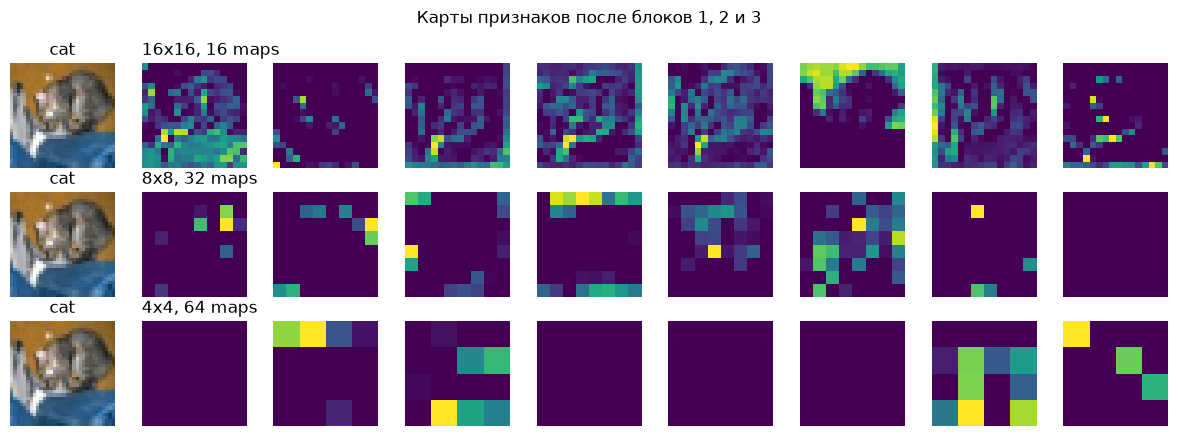

In [3]:
image, label = test[0]
maps = []
x = image[None]
with torch.no_grad():
    for layer in model.features:
        x = layer(x)
        if isinstance(layer, torch.nn.MaxPool2d):   # конец блока «свёртка → ReLU → пулинг»
            maps.append(x[0])

fig, axes = plt.subplots(3, 9, figsize=(12, 4.4))
for row, block in zip(axes, maps):
    row[0].imshow(image.permute(1, 2, 0))
    row[0].set_title(CLASSES[label])
    for ax, feature_map in zip(row[1:], block):
        ax.imshow(feature_map, cmap="viridis", interpolation="nearest")
    row[1].set_title(f"{block.shape[1]}x{block.shape[2]}, {block.shape[0]} maps", loc="left")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Карты признаков после блоков 1, 2 и 3")
plt.tight_layout()
plt.savefig("feature_maps.png", dpi=100)
show()

## 4. Кого сеть узнаёт лучше

`predict_all` возвращает вероятности `(2000, 2)`; `.argmax(1)` — номер класса с большей вероятностью.

**Таблица путаницы** 2 × 2 тем же приёмом, что в сессии 3: пара (правильный класс, ответ) → число `truth · 2 + predicted` от 0 до 3,
`bincount` считает каждое, `reshape(2, 2)` раскладывает в таблицу. Строка — правильный ответ, столбец — ответ сети.
Точность по классу — диагональ, делённая на сумму строки.

In [4]:
probs = predict_all(model, test)
predicted = probs.argmax(1)
truth = test.labels

confusion = torch.bincount(truth * 2 + predicted, minlength=4).reshape(2, 2)
print("верно\\сеть    cat    dog")
for i, name in enumerate(CLASSES):
    print(f"{name:>10} {confusion[i, 0].item():>6} {confusion[i, 1].item():>6}")
for i, name in enumerate(CLASSES_RU):
    print(f"Точность на классе «{name}»: {confusion[i, i].item() / confusion[i].sum().item():.1%}")

верно\сеть    cat    dog
       cat    814    186
       dog    148    852
Точность на классе «кошка»: 81.4%
Точность на классе «собака»: 85.2%


## 5. Самые уверенные ошибки

Самые поучительные ошибки — те, где сеть ошиблась **уверенно**:
1. `wrong` — номера картинок, где ответ неверный;
2. `probs[wrong].max(1).values` — уверенность сети в её (неверном) ответе;
3. `argsort(descending=True)` — сортируем ошибки по убыванию уверенности, берём первые 16.

Посмотрите на них: часто это необычный ракурс, плохое освещение, похожая шерсть, несколько животных
или животное, занимающее малую часть кадра. Иногда — ошибка в самих данных.

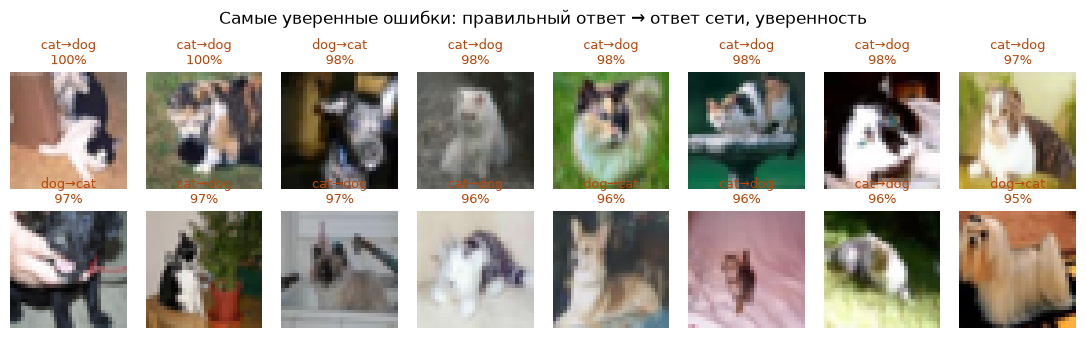

In [5]:
wrong = (predicted != truth).nonzero().flatten()
confidence = probs[wrong].max(1).values
worst = wrong[confidence.argsort(descending=True)[:16]]

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, i in zip(axes.flat, worst.tolist()):
    ax.imshow(test[i][0].permute(1, 2, 0))
    ax.set_title(f"{CLASSES[truth[i]]}→{CLASSES[predicted[i]]}\n{probs[i].max().item():.0%}",
                 color="#B8460A", fontsize=9)
    ax.axis("off")
fig.suptitle("Самые уверенные ошибки: правильный ответ → ответ сети, уверенность")
plt.tight_layout()
plt.savefig("cnn_mistakes.png", dpi=100)
show()

## Попробуйте сами

1. Нарисуйте карты признаков для собаки. Отличаются ли они от карт кошки?
2. Покажите **самые уверенные верные** ответы. Что общего у этих картинок?
3. Покажите ошибки, где сеть была **меньше всего** уверена (около 50%). Что это за картинки?
4. Загрузите сеть из шага 4 (`load_model(SimpleCNN(), "cnn")`) и сравните её фильтры с фильтрами `cnn_aug`.